<a href="https://colab.research.google.com/github/Sofia888u/S3/blob/main/Rapport_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Cellule 1: Imports (3.2)**

In [ ]:
# ============================================================
# Importation des bibliothèques nécessaires
# ============================================================
import time                        # mesurer le temps d'exécution
import numpy as np                 # calcul numérique
import pandas as pd                # manipulation de données
import matplotlib.pyplot as plt    # tracé des graphiques

# Jeux de données intégrés à Scikit-learn
from sklearn.datasets import load_breast_cancer, load_diabetes, load_iris

# Outils de préparation des données
from sklearn.model_selection import train_test_split  # séparation train/test
from sklearn.preprocessing import StandardScaler  # normalisation

# Les algorithmes étudiés
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans

# Métriques d'évaluation
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, mean_squared_error, r2_score,
    silhouette_score, adjusted_rand_score)

**Cellule 2: Préparation des données(3.3)**

In [ ]:
# 1) Chargement du jeu de données Breast Cancer
X, y = load_breast_cancer(return_X_y=True)
print("Dimensions de X :", X.shape)  # (exemples, variables)
print("Répartition des classes :", np.bincount(y))  # [malignes, bénignes]

# 2) Vérification des valeurs manquantes
print("Valeurs manquantes :", np.isnan(X).sum())

# 3) Séparation : 80 % entraînement / 20 % test
#    stratify=y garde la même proportion de classes dans les deux parties
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Entraînement :", X_train.shape, "| Test :", X_test.shape)

# 4) Normalisation : on "apprend" la moyenne et l'écart-type
#    sur l'entraînement uniquement (évite la fuite d'information)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

Dimensions de X : (569, 30)
Répartition des classes : [212 357]
Valeurs manquantes : 0
Entraînement : (455, 30) | Test : (114, 30)


**Cellule 3: Régression linéaire, exemple pizza (3.4 a)**

In [ ]:
# Données du TP0 : taille de la pizza (cm) -> prix (euros)
X_pizza = np.array([[6], [8], [10], [14], [18]])   # entrée (tableau 2D)
y_pizza = [7, 9, 13, 17.5, 18]                     # valeurs à prédire

# Création et entraînement du modèle de régression linéaire
model = LinearRegression()
model.fit(X_pizza, y_pizza)

# Paramètres appris : prix = intercept + coef * taille
print("Coefficient (pente) :", round(model.coef_[0], 3))
print("Ordonnée à l'origine :", round(model.intercept_, 3))
print("R2 :", round(model.score(X_pizza, y_pizza), 3))

# Prédiction pour une pizza de 12 cm
print("Prix prédit (12 cm) :", round(model.predict([[12]])[0], 2), "euros")

Coefficient (pente) : 0.976
Ordonnée à l'origine : 1.966
R2 : 0.91
Prix prédit (12 cm) : 13.68 euros


**Cellule 4: Régression linéaire, Diabetes (3.4 a)**

In [ ]:
# Diabetes : prédire l'évolution de la maladie (valeur numérique)
Xd, yd = load_diabetes(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(
    Xd, yd, test_size=0.2, random_state=42)

reg = LinearRegression().fit(Xd_tr, yd_tr)  # entraînement
pred = reg.predict(Xd_te)  # prédiction (jeu de test)

# Évaluation : erreur moyenne et qualité de l'ajustement
mse = mean_squared_error(yd_te, pred)
print("MSE  :", round(mse, 2))
print("RMSE :", round(mse ** 0.5, 2))
print("R2   :", round(r2_score(yd_te, pred), 2))

MSE  : 2900.19
RMSE : 53.85
R2   : 0.45


**Cellule 5: Classification, les 3 modèles (3.4 b et 3.5)**

In [ ]:
# Les trois classifieurs à comparer
models = {
    "Régression logistique": LogisticRegression(max_iter=1000),
    "SVM (noyau RBF)": SVC(kernel="rbf"),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
}

for name, m in models.items():
    debut = time.time()
    m.fit(X_train_s, y_train)   # apprentissage
    y_pred = m.predict(X_test_s)   # prédiction sur le test
    duree = time.time() - debut

    print("-----", name, "-----")
    print("Accuracy  :", round(accuracy_score(y_test, y_pred), 4))
    print("Précision :", round(precision_score(y_test, y_pred), 4))
    print("Rappel    :", round(recall_score(y_test, y_pred), 4))
    print("F1-score  :", round(f1_score(y_test, y_pred), 4))
    print("Temps (s) :", round(duree, 3))
    print("Matrice de confusion :")
    print(confusion_matrix(y_test, y_pred))

----- Régression logistique -----
Accuracy  : 0.9825
Précision : 0.9861
Rappel    : 0.9861
F1-score  : 0.9861
Temps (s) : 0.038
Matrice de confusion :
[[41  1]
 [ 1 71]]
----- SVM (noyau RBF) -----
Accuracy  : 0.9825
Précision : 0.9861
Rappel    : 0.9861
F1-score  : 0.9861
Temps (s) : 0.014
Matrice de confusion :
[[41  1]
 [ 1 71]]
----- KNN (k=5) -----
Accuracy  : 0.9561
Précision : 0.9589
Rappel    : 0.9722
F1-score  : 0.9655
Temps (s) : 0.101
Matrice de confusion :
[[39  3]
 [ 2 70]]


**Cellule 6 : Influence de K dans KNN (3.5)**

In [ ]:
# K-means sur Iris : on ignore volontairement les étiquettes (non supervisé)
iris = load_iris()
Xi = StandardScaler().fit_transform(iris.data)       # normalisation

km = KMeans(n_clusters=3, n_init=10, random_state=42)
km.fit(Xi)                                           # construction des 3 clusters

# Évaluation de la qualité du regroupement
print("Silhouette :", round(silhouette_score(Xi, km.labels_), 2))
print("ARI        :", round(adjusted_rand_score(iris.target, km.labels_), 2))
print("Inertie    :", round(km.inertia_, 2))

Silhouette : 0.46
ARI        : 0.62
Inertie    : 139.82


**Cellule 7 : K-means sur Iris (3.4 c)**

In [ ]:
# Système expert : les règles "SI ... ALORS ..." sont écrites par un expert
def diagnostic(fievre, toux, courbatures):
    # Règle 1 : fièvre élevée + toux + courbatures
    if fievre > 38 and toux and courbatures:
        return "Suspicion de grippe"
    # Règle 2 : fièvre élevée + toux
    if fievre > 38 and toux:
        return "Suspicion de bronchite"
    # Règle 3 : pas de fièvre mais toux
    if fievre <= 38 and toux:
        return "Rhume probable"
    # Règle par défaut
    return "Pas de maladie détectée"

# Test du système avec un patient (39 °C, toux, courbatures)
print(diagnostic(39.0, True, True))

Suspicion de grippe


**Cellule 8 : Système expert (3.4 d)**

In [ ]:
# Influence du paramètre K sur la performance du KNN
for k in [1, 3, 5, 7, 9, 11]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    print("K =", k, "-> accuracy =", round(knn.score(X_test_s, y_test), 4))

K = 1 -> accuracy = 0.9386
K = 3 -> accuracy = 0.9825
K = 5 -> accuracy = 0.9561
K = 7 -> accuracy = 0.9737
K = 9 -> accuracy = 0.9737
K = 11 -> accuracy = 0.9737


**Cellule 9 : Graphiques de comparaison (3.5)**

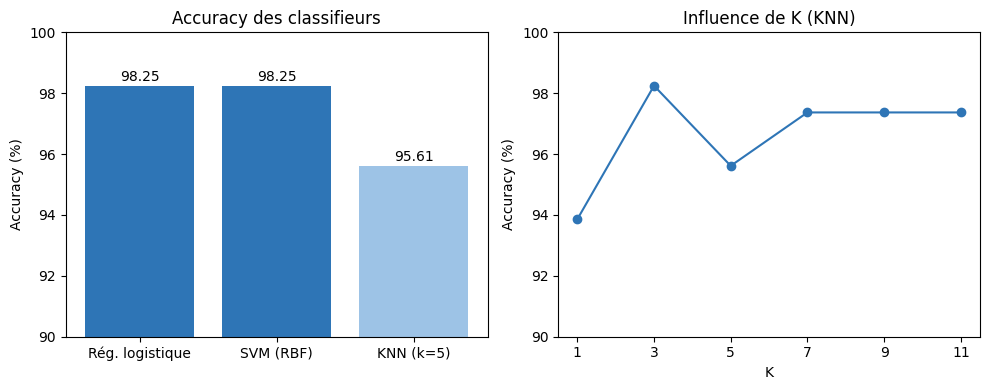

In [ ]:
# Graphique 1 : accuracy des trois classifieurs
noms = ["Rég. logistique", "SVM (RBF)", "KNN (k=5)"]
modeles = [LogisticRegression(max_iter=1000),
           SVC(kernel="rbf"),
           KNeighborsClassifier(n_neighbors=5)]
accuracies = []
for m in modeles:
    m.fit(X_train_s, y_train)                                   # apprentissage
    accuracies.append(m.score(X_test_s, y_test) * 100)          # accuracy en %

# Graphique 2 : accuracy du KNN selon la valeur de K
valeurs_k = [1, 3, 5, 7, 9, 11]
acc_k = []
for k in valeurs_k:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    acc_k.append(knn.score(X_test_s, y_test) * 100)

# Création de la figure avec 2 graphiques côte à côte
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# --- Graphique de gauche : diagramme en barres
barres = ax[0].bar(noms, accuracies, color=["#2E75B6", "#2E75B6", "#9DC3E6"])
ax[0].set_ylim(90, 100)                       # on zoome sur 90-100 % pour voir les différences
ax[0].set_ylabel("Accuracy (%)")
ax[0].set_title("Accuracy des classifieurs")
for b, v in zip(barres, accuracies):          # affiche la valeur au-dessus de chaque barre
    ax[0].text(b.get_x() + b.get_width() / 2, v + 0.15, f"{v:.2f}", ha="center")

# --- Graphique de droite : courbe
ax[1].plot(valeurs_k, acc_k, marker="o", color="#2E75B6")
ax[1].set_xticks(valeurs_k)
ax[1].set_ylim(90, 100)
ax[1].set_xlabel("K")
ax[1].set_ylabel("Accuracy (%)")
ax[1].set_title("Influence de K (KNN)")

plt.tight_layout()
plt.show()